# 05 · Final evaluation on the test set
21 unseen patients (DS2 minus record 202). Opened once. All models frozen: RF + CNN A and B × 3 seeds.

## Prediction (written before opening the test set)
- My prediction: ...

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile /content/drive/MyDrive/ECG_Arrhythmia_Classification/src/features.py
import numpy as np
from config import BEFORE, FS

R = BEFORE
SHAPE_COLS = ['r_amp', 'q_amp', 's_amp', 'qrs_width_ms', 'qrs_area',
              't_max', 't_min', 'beat_std', 'peak_to_peak']

def qrs_width_ms(a, max_half=40):
    half = 0.5 * a[R]
    l = R
    while l > R - max_half and a[l] > half:
        l -= 1
    r = R
    while r < R + max_half and a[r] > half:
        r += 1
    return (r - l) / FS * 1000

def shape_features(X_mv):
    x = X_mv - np.median(X_mv[:, :60], axis=1, keepdims=True)
    a = np.abs(x)
    return np.column_stack([
        x[:, R],
        x[:, R - 30:R].min(axis=1),
        x[:, R:R + 30].min(axis=1),
        np.array([qrs_width_ms(row) for row in a]),
        a[:, R - 20:R + 30].sum(axis=1) / FS,
        x[:, R + 50:].max(axis=1),
        x[:, R + 50:].min(axis=1),
        x.std(axis=1),
        x.max(axis=1) - x.min(axis=1),
    ]).astype(np.float32)

def rf_features(d):
    """8 RR features + 9 shape features, same order as Phase 4."""
    return np.hstack([d['rr'], shape_features(d['X_mv'])])

Writing /content/drive/MyDrive/ECG_Arrhythmia_Classification/src/features.py


In [4]:

import sys
sys.path.append('/content/drive/MyDrive/ECG_Arrhythmia_Classification/src')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

from config import *
from eval_utils import evaluate
from features import rf_features

def load(name):
    d = np.load(f'{PROC_DIR}/{name}.npz')
    return {k: d[k] for k in d.files}

with open(f'{MODEL_DIR}/rr_scaler.json') as f:
    sc = json.load(f)
rr_mean, rr_std = np.array(sc['mean']), np.array(sc['std'])

def cnn_inputs(d, use_rr):
    X = d['X'][..., None]
    return [X, ((d['rr'] - rr_mean) / rr_std).astype('float32')] if use_rr else X

rf = joblib.load(f'{MODEL_DIR}/rf_best.joblib')
CNN_NAMES = [f'cnn_{v}_seed{s}' for v in ['A_beat', 'B_beat_rr'] for s in [42, 1, 2]]
cnns = {n: tf.keras.models.load_model(f'{MODEL_DIR}/{n}.keras') for n in CNN_NAMES}
print("Loaded RF +", len(cnns), "CNNs")

Loaded RF + 6 CNNs


In [6]:
val = load('val')
print("RF val macro-F1:", evaluate(val['y'], rf.predict(rf_features(val)), val['cls'])['macro_f1'], "(expect 0.9367)")
p = (cnns['cnn_B_beat_rr_seed42'].predict(cnn_inputs(val, True), batch_size=2048, verbose=0).ravel() >= 0.5).astype(int)
print("CNN B seed42 val macro-F1:", evaluate(val['y'], p, val['cls'])['macro_f1'], "(expect 0.8749)")

RF val macro-F1: 0.9367 (expect 0.9367)
CNN B seed42 val macro-F1: 0.8749 (expect 0.8749)


In [7]:
test = load('test')
print("Test:", test['X'].shape, "| patients:", len(np.unique(test['record'])))

preds, probs = {}, {}
preds['rf_best'] = rf.predict(rf_features(test))
probs['rf_best'] = rf.predict_proba(rf_features(test))[:, 1]
for n, m in cnns.items():
    probs[n] = m.predict(cnn_inputs(test, 'B_beat' in n), batch_size=2048, verbose=0).ravel()
    preds[n] = (probs[n] >= 0.5).astype(int)

np.savez_compressed(f'{RES_DIR}/test_predictions.npz', y=test['y'], cls=test['cls'],
                    record=test['record'], **{f'prob_{k}': v for k, v in probs.items()})

rows = [{'model': 'Lazy (always Normal)', **evaluate(test['y'], np.zeros_like(test['y']), test['cls'])}]
rows += [{'model': k, **evaluate(test['y'], p, test['cls'])} for k, p in preds.items()]
res = pd.DataFrame(rows).set_index('model')
res.to_csv(f'{RES_DIR}/test_metrics_all_models.csv')
print(res)

group = lambda n: 'RF' if n == 'rf_best' else 'CNN A' if 'A_beat' in n else 'CNN B' if 'B_beat' in n else 'Lazy'
summary = res.groupby(res.index.map(group)).agg(['mean', 'std']).round(3)
summary.to_csv(f'{RES_DIR}/test_summary.csv')
print("\n=== Test, mean ± std over seeds ===")
print(summary[['macro_f1', 'ab_precision', 'ab_recall', 'recall_S', 'recall_V', 'recall_F']])

Test: (47527, 252) | patients: 21
                      macro_f1  ab_precision  ab_recall  recall_S  recall_V  \
model                                                                         
Lazy (always Normal)    0.4701        0.0000     0.0000    0.0000    0.0000   
rf_best                 0.7476        0.4687     0.7187    0.1954    0.9828   
cnn_A_beat_seed42       0.6928        0.3865     0.6194    0.1510    0.9366   
cnn_A_beat_seed1        0.6749        0.3687     0.5496    0.0511    0.8728   
cnn_A_beat_seed2        0.7341        0.5415     0.5127    0.0062    0.8447   
cnn_B_beat_rr_seed42    0.8984        0.8527     0.7874    0.5351    0.9894   
cnn_B_beat_rr_seed1     0.8133        0.6108     0.7509    0.5104    0.9641   
cnn_B_beat_rr_seed2     0.8722        0.8992     0.6727    0.2527    0.9725   

                      recall_F  
model                           
Lazy (always Normal)    0.0000  
rf_best                 0.9432  
cnn_A_beat_seed42       0.1525  
cnn_A_beat

In [8]:
rf_val = json.load(open(f'{RES_DIR}/rf_val_metrics.json'))['val']['macro_f1']
cnn_val = pd.read_csv(f'{RES_DIR}/cnn_seeds_val.csv').groupby('variant')['macro_f1'].mean()
vt = pd.DataFrame({
    'val_macro_f1':  [rf_val, cnn_val['cnn_A'], cnn_val['cnn_B']],
    'test_macro_f1': [summary.loc[g, ('macro_f1', 'mean')] for g in ['RF', 'CNN A', 'CNN B']],
}, index=['RF', 'CNN A', 'CNN B']).round(3)
vt['drop'] = (vt['val_macro_f1'] - vt['test_macro_f1']).round(3)
vt.to_csv(f'{RES_DIR}/val_vs_test.csv')
print(vt)

       val_macro_f1  test_macro_f1   drop
RF            0.937          0.748  0.189
CNN A         0.742          0.701  0.041
CNN B         0.848          0.861 -0.013


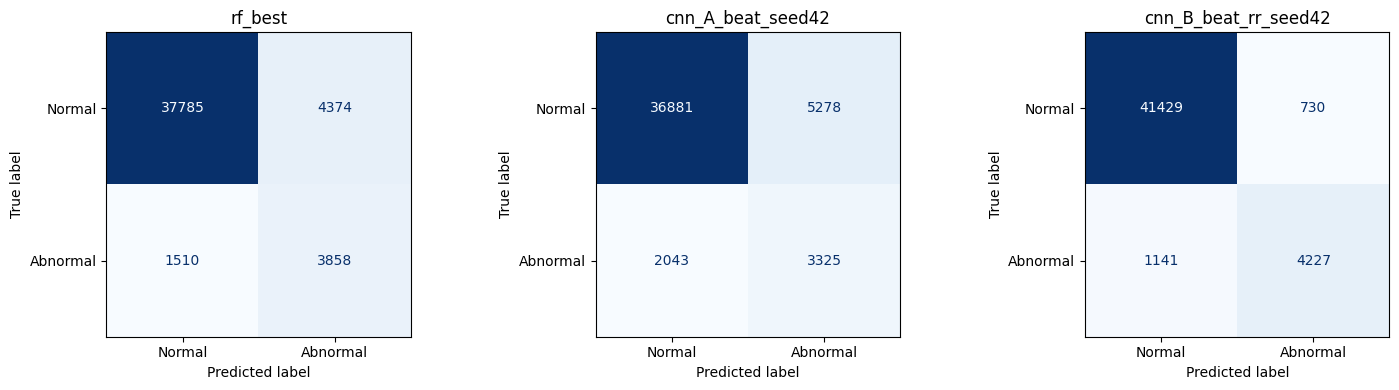

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, ['rf_best', 'cnn_A_beat_seed42', 'cnn_B_beat_rr_seed42']):
    ConfusionMatrixDisplay.from_predictions(test['y'], preds[n], display_labels=['Normal', 'Abnormal'],
                                            cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(n)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/11_test_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

        beats     S    V    F  RF_recall  RF_false_alarms  CNN_B_recall  CNN_B_false_alarms
record                                                                                     
100      2271    33    1    0      1.000              1.0         0.186                 0.0
103      2082     2    0    0      0.500              0.0         0.000                 1.0
105      2565     0   41    0      0.976             38.0         1.000               107.0
111      2122     0    1    0      1.000              1.0         1.000                80.3
113      1793     6    0    0      1.000              5.0         1.000                70.3
117      1533     1    0    0      1.000              5.0         1.000               245.7
121      1861     1    1    0      1.000              0.0         0.833                 5.0
123      1516     0    3    0      1.000              3.0         1.000                 1.3
200      2599    30  825    2      0.958              5.0         0.944         

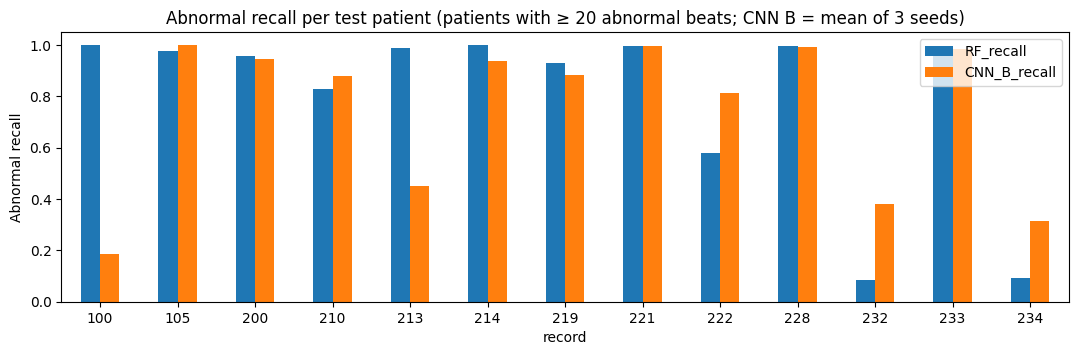

In [10]:
cnnB = [n for n in preds if 'B_beat' in n]
rows = []
for r in TEST_RECORDS:
    m = test['record'] == r
    y, c = test['y'][m], test['cls'][m]
    row = {'record': r, 'beats': int(m.sum()), 'S': int((c == 'S').sum()),
           'V': int((c == 'V').sum()), 'F': int((c == 'F').sum())}
    for label, names in [('RF', ['rf_best']), ('CNN_B', cnnB)]:
        row[f'{label}_recall'] = round(np.mean([preds[n][m][y == 1].mean() for n in names]), 3) if y.sum() else np.nan
        row[f'{label}_false_alarms'] = round(np.mean([preds[n][m][y == 0].sum() for n in names]), 1)
    rows.append(row)

pp = pd.DataFrame(rows).set_index('record')
pp.to_csv(f'{RES_DIR}/test_per_patient.csv')
print(pp.to_string())

has_ab = pp[(pp.S + pp.V + pp.F) >= 20]
has_ab[['RF_recall', 'CNN_B_recall']].plot(kind='bar', figsize=(13, 3.5), rot=0)
plt.ylabel('Abnormal recall')
plt.title('Abnormal recall per test patient (patients with ≥ 20 abnormal beats; CNN B = mean of 3 seeds)')
plt.savefig(f'{FIG_DIR}/12_test_recall_per_patient.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
rng = np.random.default_rng(SEED)
idx_by_rec = {r: np.where(test['record'] == r)[0] for r in TEST_RECORDS}

rf_s, cb_s, diff = [], [], []
for _ in range(1000):
    recs = rng.choice(TEST_RECORDS, size=len(TEST_RECORDS), replace=True)   # resample PATIENTS
    idx = np.concatenate([idx_by_rec[r] for r in recs])
    y = test['y'][idx]
    f_rf = f1_score(y, preds['rf_best'][idx], average='macro')
    f_cb = np.mean([f1_score(y, preds[n][idx], average='macro') for n in cnnB])
    rf_s.append(f_rf); cb_s.append(f_cb); diff.append(f_rf - f_cb)

ci = lambda a: np.percentile(a, [2.5, 97.5]).round(3)
print("RF    macro-F1 95% CI:", ci(rf_s))
print("CNN B macro-F1 95% CI:", ci(cb_s))
print("RF − CNN B        CI:", ci(diff))
print(f"RF wins in {100 * np.mean(np.array(diff) > 0):.1f}% of resamples")

json.dump({'rf_ci': ci(rf_s).tolist(), 'cnnB_ci': ci(cb_s).tolist(), 'diff_ci': ci(diff).tolist(),
           'rf_win_pct': float(100 * np.mean(np.array(diff) > 0))},
          open(f'{RES_DIR}/test_bootstrap.json', 'w'), indent=2)

RF    macro-F1 95% CI: [0.634 0.914]
CNN B macro-F1 95% CI: [0.782 0.927]
RF − CNN B        CI: [-0.204  0.029]
RF wins in 5.4% of resamples


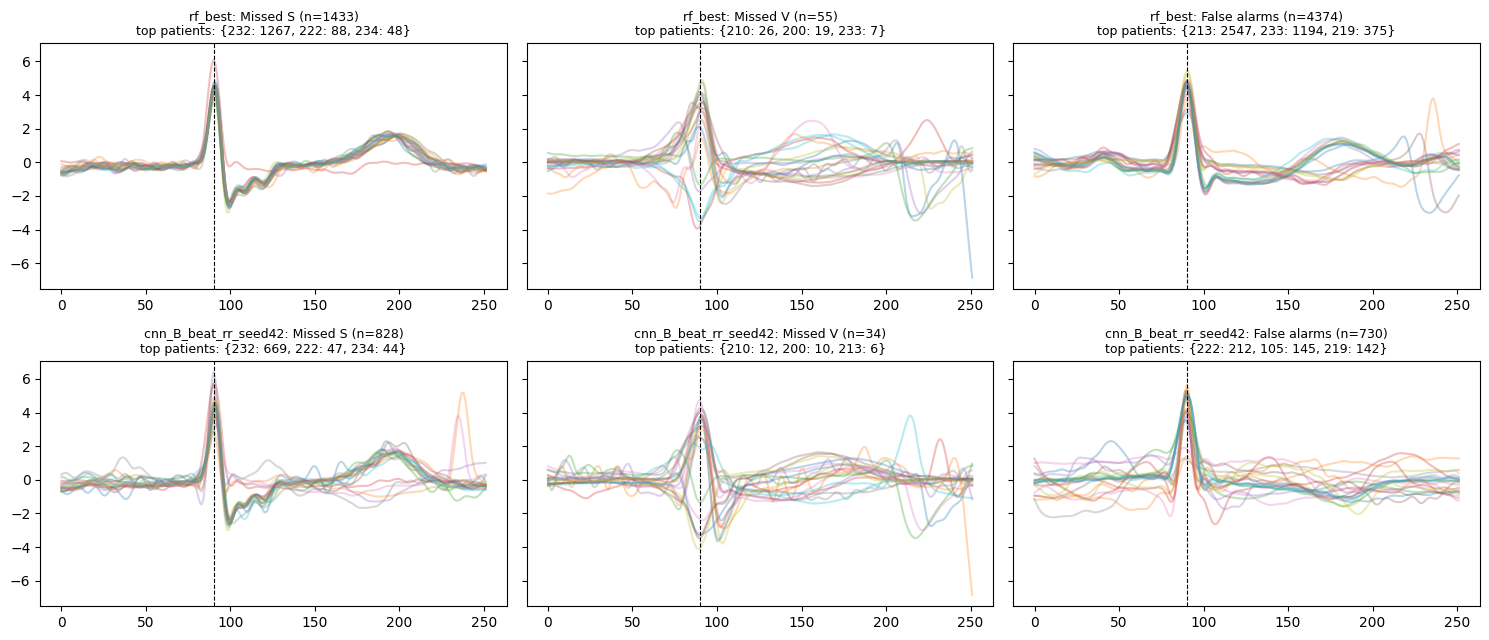

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharey=True)
for row, n in enumerate(['rf_best', 'cnn_B_beat_rr_seed42']):
    p = preds[n]
    groups = [('Missed S', (test['cls'] == 'S') & (p == 0)),
              ('Missed V', (test['cls'] == 'V') & (p == 0)),
              ('False alarms', (test['y'] == 0) & (p == 1))]
    for col, (title, mask) in enumerate(groups):
        ax = axes[row, col]
        idx = np.where(mask)[0]
        for i in np.random.default_rng(SEED).choice(idx, size=min(20, len(idx)), replace=False):
            ax.plot(test['X'][i], alpha=0.3)
        ax.axvline(BEFORE, color='k', ls='--', lw=0.8)
        top = pd.Series(test['record'][mask]).value_counts().head(3).to_dict()
        ax.set_title(f'{n}: {title} (n={mask.sum()})\ntop patients: {top}', fontsize=9)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/13_test_misclassified_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## Post-hoc diagnostics (after test evaluation)
Exploratory analysis to explain the results. No model is changed or re-selected based on this.

Training patients' median RR range: 0.578 – 1.028 s
        median_rr_s  rr_irregularity  S_share_%  RF_false_alarm_%  CNNB_false_alarm_%
record                                                                               
213           0.556            0.048        0.9              96.5                 0.2
233           0.589            0.147        0.2              53.6                 5.7
219           0.803            0.280        0.3              18.0                 3.4
210           0.686            0.139        0.8               3.4                 2.2
222           0.761            0.268        8.4               3.3                14.1
221           0.711            0.238        0.0               1.8                 3.1
105           0.703            0.077        0.0               1.5                 4.2
117           1.181            0.034        0.1               0.3                16.0
113           1.014            0.094        0.3               0.3                 3.9
20

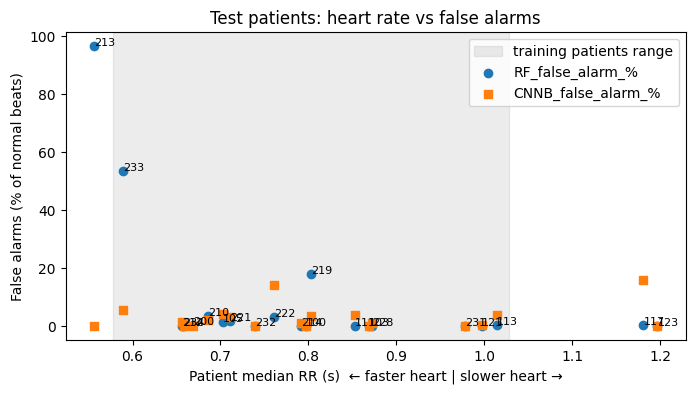


Patient 232, median RR features:
     pre_rr  long_rr  rel_pre_long
cls                               
N     1.872    0.739         2.545
S     0.731    0.739         0.992


In [13]:
train = load('train')

# 1) Heart rate of each patient vs RF false-alarm rate
tr_rr = pd.Series({r: np.median(train['rr'][train['record'] == r, 0]) for r in TRAIN_RECORDS})
print(f"Training patients' median RR range: {tr_rr.min():.3f} – {tr_rr.max():.3f} s")

rows = []
for r in TEST_RECORDS:
    m = test['record'] == r
    y = test['y'][m]
    rr_norm = test['rr'][m][y == 0, 0]
    rows.append({'record': r,
                 'median_rr_s': round(np.median(test['rr'][m, 0]), 3),
                 'rr_irregularity': round(rr_norm.std() / np.median(rr_norm), 3),
                 'S_share_%': round(100 * (test['cls'][m] == 'S').mean(), 1),
                 'RF_false_alarm_%': round(100 * preds['rf_best'][m][y == 0].mean(), 1),
                 'CNNB_false_alarm_%': round(100 * np.mean([preds[n][m][y == 0].mean() for n in cnnB]), 1)})
diag = pd.DataFrame(rows).set_index('record').sort_values('RF_false_alarm_%', ascending=False)
diag.to_csv(f'{RES_DIR}/test_posthoc_diagnostics.csv')
print(diag.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(tr_rr.min(), tr_rr.max(), color='grey', alpha=0.15, label='training patients range')
for col, mk in [('RF_false_alarm_%', 'o'), ('CNNB_false_alarm_%', 's')]:
    ax.scatter(diag['median_rr_s'], diag[col], marker=mk, label=col)
for r, row in diag.iterrows():
    ax.annotate(str(r), (row['median_rr_s'], row['RF_false_alarm_%']), fontsize=8)
ax.set_xlabel('Patient median RR (s)  ← faster heart | slower heart →')
ax.set_ylabel('False alarms (% of normal beats)')
ax.legend(); ax.set_title('Test patients: heart rate vs false alarms')
plt.savefig(f'{FIG_DIR}/14_posthoc_rr_vs_false_alarms.png', dpi=150, bbox_inches='tight')
plt.show()

# 2) Patient 232: does the long-term reference break when S beats are the majority?
m = test['record'] == 232
d232 = pd.DataFrame(test['rr'][m], columns=RR_COLS)
d232['cls'] = test['cls'][m]
print("\nPatient 232, median RR features:")
print(d232.groupby('cls')[['pre_rr', 'long_rr', 'rel_pre_long']].median().round(3))

## Key findings (test set, 21 unseen patients, opened once)

**Sanity check:** reloaded models reproduced the validation scores exactly (RF 0.9367, CNN B seed 42 0.8749).

**Results (macro-F1):**

| Model | Validation | Test | Change |
|---|---|---|---|
| Lazy (always Normal) | 0.488 | 0.470 | n/a |
| RF (RR + shape) | 0.937 | 0.748 | −0.189 |
| CNN A (raw beat, 3 seeds) | 0.742 | 0.701 ± 0.030 | −0.041 |
| **CNN B (beat + RR, 3 seeds)** | 0.848 | **0.861 ± 0.044** | +0.013 |

- **The validation ranking reversed on test:** CNN B beats the RF on unseen patients (precision 0.79 vs 0.47, S recall 0.43 vs 0.20).
- **Patient bootstrap (1,000 resamples):** RF − CNN B = −0.204 to +0.029; RF wins in only 5.4% → CNN B is **probably** better, but the evidence is suggestive, not conclusive (21 patients).
- **V beats are solved by both models** (recall ~0.98).
- **Errors are patient-clustered:** RF false alarms come mainly from 213 (2,547), 233 (1,194) and 219 (375); most missed S beats come from patient 232 (1,267 of 1,433).
- RF's F recall (0.94) is not meaningful: it flagged ~96% of patient 213's normal beats too.

**Post-hoc diagnostics (explaining

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


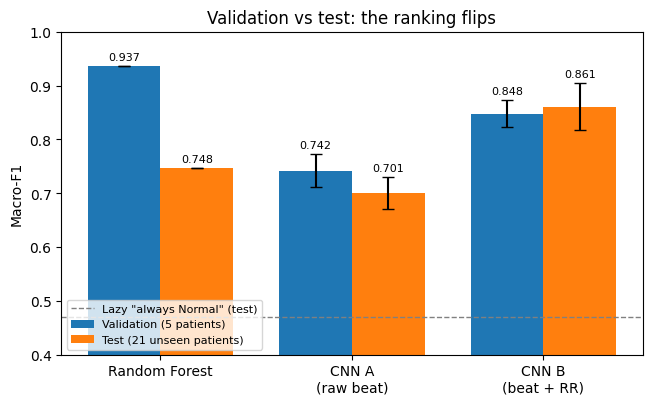

In [14]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ECG_Arrhythmia_Classification/src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import *

vt = pd.read_csv(f'{RES_DIR}/val_vs_test.csv', index_col=0)
summ = pd.read_csv(f'{RES_DIR}/test_summary.csv', header=[0, 1], index_col=0)
seeds_val = pd.read_csv(f'{RES_DIR}/cnn_seeds_val.csv').groupby('variant')['macro_f1'].std()

val_err  = [0, seeds_val['cnn_A'], seeds_val['cnn_B']]
test_err = [0, summ.loc['CNN A', ('macro_f1', 'std')], summ.loc['CNN B', ('macro_f1', 'std')]]
x, w = np.arange(3), 0.38

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(x - w/2, vt['val_macro_f1'],  w, yerr=val_err,  capsize=4, label='Validation (5 patients)')
ax.bar(x + w/2, vt['test_macro_f1'], w, yerr=test_err, capsize=4, label='Test (21 unseen patients)')
ax.axhline(0.470, ls='--', color='grey', lw=1, label='Lazy "always Normal" (test)')
for i in range(3):
    ax.text(i - w/2, vt['val_macro_f1'].iloc[i] + val_err[i] + 0.01, f"{vt['val_macro_f1'].iloc[i]:.3f}", ha='center', fontsize=8)
    ax.text(i + w/2, vt['test_macro_f1'].iloc[i] + test_err[i] + 0.01, f"{vt['test_macro_f1'].iloc[i]:.3f}", ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(['Random Forest', 'CNN A\n(raw beat)', 'CNN B\n(beat + RR)'])
ax.set_ylabel('Macro-F1'); ax.set_ylim(0.4, 1.0); ax.legend(loc='lower left', fontsize=8)
ax.set_title('Validation vs test: the ranking flips')
plt.savefig(f'{FIG_DIR}/00_results_summary.png', dpi=150, bbox_inches='tight')
plt.show()